In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from google.colab import drive

drive.mount("/content/drive")

DATA_DIR = "/content/drive/MyDrive/Хакатон Газпром"
RAW_PATH = os.path.join(DATA_DIR, "hakhathon_data.csv")
FEAT_PATH = os.path.join(DATA_DIR, "features_v1.parquet")

df = pd.read_csv(RAW_PATH)
df["Time"] = pd.to_datetime(df["Time"], format="%d.%m.%Y %H:%M:%S")
df = df.sort_values("ID").reset_index(drop=True)

# Считаем интервал между строками, чтобы не сглаживать и не дифференцировать через разрывы
dt = df["Time"].diff().dt.total_seconds().fillna(5.0).to_numpy()
gaps = np.where(dt > 10)[0]

print("Размер датасета:", df.shape)
print("Временных разрывов > 10 сек:", len(gaps))
print("Крупных разрывов > 60 сек:", int((dt > 60).sum()))

Mounted at /content/drive
Размер датасета: (180901, 12)
Временных разрывов > 10 сек: 17
Крупных разрывов > 60 сек: 3


In [ ]:
# Центрированная скорость (смотрим одинаково влево и вправо, не перешагиваем разрывы dt > 10)
def get_centered_slope(arr, half_w, dt_arr, gap_thr=10.0):
    cuts = np.where(dt_arr > gap_thr)[0]
    bounds = np.r_[0, cuts, len(arr)]
    res = np.zeros(len(arr), dtype=np.float32)

    for a, b in zip(bounds[:-1], bounds[1:]):
        seg = arr[a:b]
        n = len(seg)
        if n <= 2:
            continue
        idx = np.arange(n)
        lo = np.maximum(0, idx - half_w)
        hi = np.minimum(n - 1, idx + half_w)
        res[a:b] = (seg[hi] - seg[lo]) / np.maximum(hi - lo, 1)
    return res

# Чистим аппаратные сбои в минус
bp = np.clip(df["BitPosition"].to_numpy(), 0.0, None)
rop = np.clip(df["ROP"].to_numpy(), 0.0, None)
flow = np.clip(df["InletFlow"].to_numpy(), 0.0, None)
pres = np.clip(df["ManifoldPressure"].to_numpy(), 0.0, None)
rot = np.clip(df["Turn_rotor"].to_numpy(), 0.0, None)
wedge = np.clip(df["WedgePosition"].to_numpy(), 0.0, 1.5)
hl = np.clip(df["HL"].to_numpy(), 0.0, None)
load = np.clip(df["Load"].to_numpy(), 0.0, None)

# Плавные центрированные скорости (окно +-12 строк = +-1 минута)
bit_slope = np.clip(get_centered_slope(bp, 12, dt), -5.0, 5.0)
depth_slope = np.clip(get_centered_slope(df["Depth"].to_numpy(), 12, dt), -0.2, 1.0)

if os.path.exists(FEAT_PATH):
    feat_nik = pd.read_parquet(FEAT_PATH).sort_values("ID").reset_index(drop=True)
    blk_range = feat_nik["block_range_30s"].fillna(0.0).clip(0.0, 30.0).to_numpy()
    print("Подгрузили block_range_30s из features_v1.parquet")
else:
    blk_s = df["TravelingBlockPosition"]
    blk_range = (blk_s.rolling(6, min_periods=1).max() - blk_s.rolling(6, min_periods=1).min()).fillna(0.0).clip(0.0, 30.0).to_numpy()
    print("Посчитали block_range_30s напрямую из сырых данных")

feat_df = pd.DataFrame({
    "BitPosition": bp,
    "ROP": rop,
    "InletFlow": flow,
    "ManifoldPressure": pres,
    "Turn_rotor": rot,
    "WedgePosition": wedge,
    "HL": hl,
    "Load": load,
    "flow_on": (flow > 1.5).astype(np.float32),
    "on_bottom": (bp < 2.0).astype(np.float32),
    "bit_slope": bit_slope,
    "depth_slope": depth_slope,
    "block_range_30s": blk_range,
})

weights = np.array([1.0, 1.1, 1.1, 0.9, 1.1, 1.35, 1.0, 1.0, 0.8, 0.8, 1.0, 1.0, 0.6], dtype=np.float32)
X = StandardScaler().fit_transform(feat_df.to_numpy())
X = np.clip(X, -6.0, 6.0).astype(np.float32) * weights

print("Матрица признаков готова:", X.shape)

Подгрузили block_range_30s из features_v1.parquet
Матрица признаков готова: (180901, 13)


In [ ]:
seeds = [0, 21, 42, 123, 777]
probas_list = []
preds_list = []

for s in seeds:
    km = KMeans(n_clusters=9, n_init=15, max_iter=400, random_state=s)
    km.fit(X[::3])  # учим на каждой 3-й точке, работает в 3 раза быстрее при том же качестве

    # Переводим расстояния до центроидов в мягкие вероятности (softmax)
    d2 = np.stack([np.sum((X - c) ** 2, axis=1) for c in km.cluster_centers_], axis=1)
    ex = np.exp(np.clip(-(d2 - d2.min(axis=1, keepdims=True)) / 3.0, -30.0, 0.0))
    proba = (ex / ex.sum(axis=1, keepdims=True)).astype(np.float32)

    probas_list.append(proba)
    preds_list.append(np.argmax(proba, axis=1))

# Проверяем стабильность кластеров между разными сидами
aris = [round(adjusted_rand_score(preds_list[0], p), 4) for p in preds_list[1:]]
print("Стабильность 5 сидов (ARI vs seed=0):", aris)

ref_pred = preds_list[2]
aligned_probas = []

for proba, pred in zip(probas_list, preds_list):
    cm = np.zeros((9, 9), dtype=np.int64)
    np.add.at(cm, (ref_pred, pred), 1)
    rows, cols = linear_sum_assignment(-cm)

    p_new = np.zeros_like(proba)
    for r, c in zip(rows, cols):
        p_new[:, r] = proba[:, c]
    aligned_probas.append(p_new)

proba_5seed = np.mean(aligned_probas, axis=0).astype(np.float32)
print("Средние вероятности собраны:", proba_5seed.shape)

Стабильность 5 сидов (ARI vs seed=0): [0.9998, 0.9999, 0.9995, 0.9998]
Средние вероятности собраны: (180901, 9)


In [ ]:
# Считаем величину мгновенного скачка по 8 основным датчикам
X_inst = np.clip(StandardScaler().fit_transform(feat_df.iloc[:, :8].to_numpy()), -6.0, 6.0)
jump = np.zeros(len(df), dtype=np.float32)
jump[1:] = np.linalg.norm(X_inst[1:] - X_inst[:-1], axis=1)

# Определяем зоны активного быстрого СПО (насос выкл + сильный наклон BitPosition)
bit_slope_w20 = np.clip(get_centered_slope(bp, 20, dt), -5.0, 5.0)
active_tripping = (flow < 1.0) & (np.abs(bit_slope_w20) > 0.65)

# Глушим детектор скачков на частых щелчках клиньев внутри СПО
jump_clean = jump.copy()
jump_clean[active_tripping] *= 0.20

# Ставим границы на пиках скачков, на входе/выходе из СПО и на всех временных разрывах
thr = float(np.percentile(jump, 97.0))
peaks, _ = find_peaks(jump_clean, height=thr, distance=5)
trip_edges = np.where(np.diff(active_tripping.astype(np.int8)) != 0)[0] + 1
cp_bounds = np.unique(np.r_[0, peaks, trip_edges, gaps, len(df)])

print("Найдено атомарных отрезков:", len(cp_bounds) - 1)

# Усредняем вероятности внутри каждого отрезка — теперь смена класса возможна только на реальных скачках
proba_atomic = np.empty_like(proba_5seed)
for k in range(len(cp_bounds) - 1):
    a, b = cp_bounds[k], cp_bounds[k + 1]
    proba_atomic[a:b] = proba_5seed[a:b].mean(axis=0, keepdims=True)

Найдено атомарных отрезков: 3663


In [ ]:
def viterbi_smooth(proba, stay_bonus=15.0):
    T, K = proba.shape
    log_p = np.log(np.clip(proba, 1e-9, 1.0))
    dp = np.zeros((T, K), dtype=np.float64)
    back = np.zeros((T, K), dtype=np.int32)
    dp[0] = log_p[0]

    for t in range(1, T):
        prev = dp[t - 1]
        best_i = int(np.argmax(prev))
        best_v = prev[best_i]
        stay_v = prev + stay_bonus

        keep = stay_v >= best_v
        dp[t] = log_p[t] + np.where(keep, stay_v, best_v)
        back[t] = np.where(keep, np.arange(K), best_i)

    path = np.zeros(T, dtype=np.int8)
    path[-1] = int(np.argmax(dp[-1]))
    for t in range(T - 2, -1, -1):
        path[t] = back[t + 1, path[t + 1]]
    return path

# Запускаем Viterbi отдельно на каждом непрерывном куске между разрывами dt > 10
def viterbi_gap_aware(proba, dt_arr, stay_bonus=15.0, gap_thr=10.0):
    cuts = np.where(dt_arr > gap_thr)[0]
    bounds = np.r_[0, cuts, len(proba)]
    out = np.empty(len(proba), dtype=np.int8)

    for a, b in zip(bounds[:-1], bounds[1:]):
        if b - a <= 2:
            out[a:b] = np.argmax(proba[a:b], axis=1)
        else:
            out[a:b] = viterbi_smooth(proba[a:b], stay_bonus=stay_bonus)
    return out

# Убираем короткие выбросы (< min_len строк) внутри непрерывных интервалов
def clean_short_segments(labels, dt_arr, min_len=3, gap_thr=10.0):
    cuts = np.where(dt_arr > gap_thr)[0]
    bounds = np.r_[0, cuts, len(labels)]
    out = labels.copy()

    for a, b in zip(bounds[:-1], bounds[1:]):
        seg = out[a:b].copy()
        if len(seg) <= min_len:
            continue
        while True:
            ch = np.where(np.diff(seg) != 0)[0] + 1
            st = np.r_[0, ch]
            en = np.r_[ch, len(seg)]
            ln = en - st
            short = np.where(ln < min_len)[0]
            if len(short) == 0 or len(ln) <= 1:
                break
            idx = int(short[np.argmin(ln[short])])
            s0, s1 = st[idx], en[idx]
            if idx == 0:
                seg[s0:s1] = seg[en[0]]
            elif idx == len(ln) - 1:
                seg[s0:s1] = seg[st[idx] - 1]
            else:
                seg[s0:s1] = seg[s0 - 1] if ln[idx - 1] >= ln[idx + 1] else seg[s1]
        out[a:b] = seg
    return out

pred_final = viterbi_gap_aware(proba_atomic, dt, stay_bonus=15.0)
pred_final = clean_short_segments(pred_final, dt, min_len=3)
print("Финальная разметка готова!")

Финальная разметка готова!


In [ ]:
changes = np.where(np.diff(pred_final) != 0)[0] + 1
seg_lens = np.diff(np.r_[0, changes, len(pred_final)])

print("Всего сегментов:", len(seg_lens))
print("Медианная длина сегмента (строк):", int(np.median(seg_lens)))
print("Коротких выбросов (1-2 строки):", int((seg_lens <= 2).sum()))

check_cols = [
    "BitPosition", "ROP", "InletFlow", "ManifoldPressure",
    "Turn_rotor", "WedgePosition", "HL", "Load", "TravelingBlockPosition"
]

passport_df = df[check_cols].copy()
passport_df["cluster"] = pred_final
passport_df["d60_bit"] = df["BitPosition"].diff(60).fillna(0.0)
passport_df["d60_depth"] = df["Depth"].diff(60).fillna(0.0)

passport = passport_df.groupby("cluster")[check_cols].median().round(2)
passport["d60_bit_mean"] = passport_df.groupby("cluster")["d60_bit"].mean().round(2)
passport["d60_depth_mean"] = passport_df.groupby("cluster")["d60_depth"].mean().round(3)
passport["share_%"] = (passport_df["cluster"].value_counts().sort_index() / len(df) * 100).round(2)

display(passport)

Всего сегментов: 988
Медианная длина сегмента (строк): 34
Коротких выбросов (1-2 строки): 0


,BitPosition,ROP,InletFlow,ManifoldPressure,Turn_rotor,WedgePosition,HL,Load,TravelingBlockPosition,d60_bit_mean,d60_depth_mean,share_%
cluster,,,,,,,,,,,,
0,3226.00,0.37,0.00,0.17,0.15,0.00,11.46,0.00,13.98,-1.71,-0.000,16.87
1,1.96,1.06,12.32,14.39,0.27,1.08,57.16,0.99,13.09,-0.48,0.260,9.28
2,1744.00,0.83,0.00,0.25,0.20,-0.00,11.75,0.00,24.57,-49.24,0.000,5.71
3,0.32,14.38,13.60,18.29,39.03,1.03,54.80,2.64,15.03,-0.08,1.206,8.46
4,345.28,0.83,0.00,0.27,0.23,-0.02,11.94,50.28,25.82,8.08,0.003,7.59
5,67.86,0.83,7.95,7.57,47.18,1.00,64.94,0.62,14.52,0.58,0.004,17.09
6,2226.86,0.83,0.00,0.17,0.18,-0.02,12.78,0.00,23.28,45.45,0.000,2.86
7,73.23,0.83,0.00,0.25,0.25,-0.04,21.69,0.00,19.10,1.39,0.000,7.86
8,17.03,0.83,0.00,0.25,0.33,1.00,67.72,0.83,16.26,-0.16,0.002,24.29


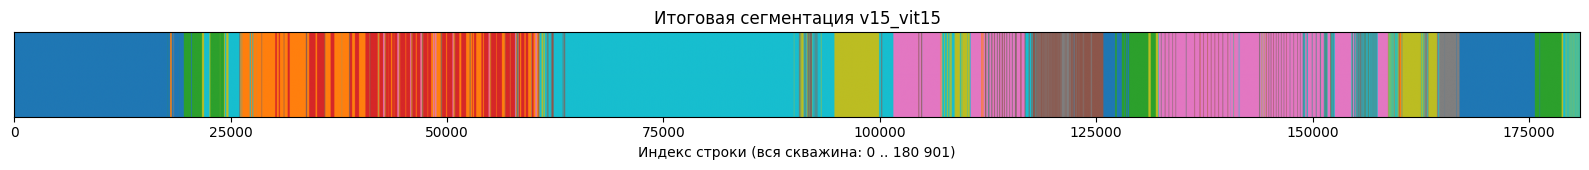

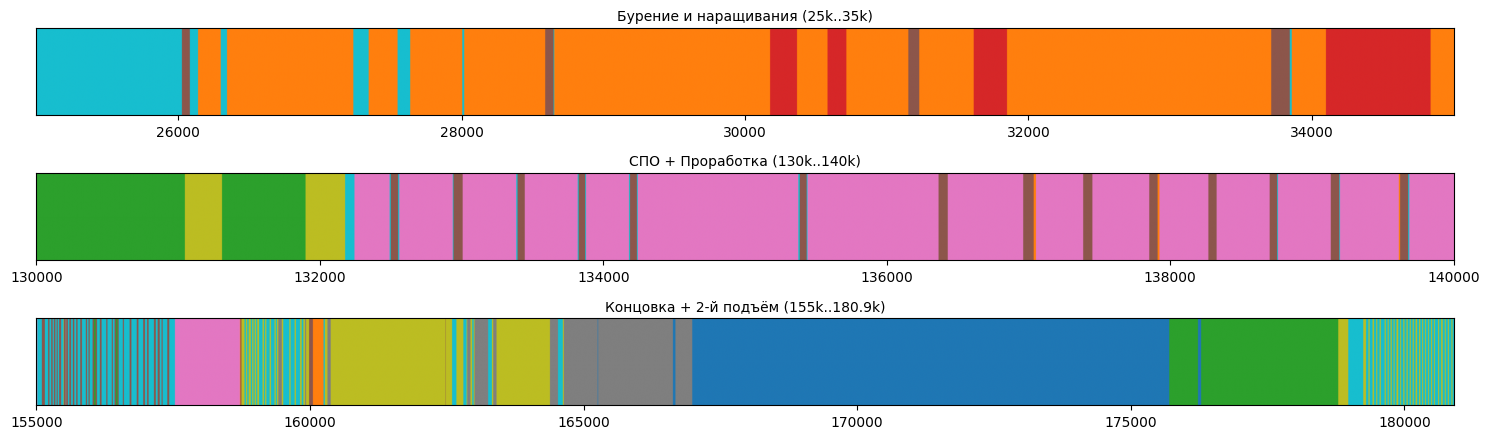

In [ ]:
# Общая картина по всей скважине
plt.figure(figsize=(16, 1.8))
plt.imshow(pred_final[::10][None, :], aspect="auto", cmap="tab10", vmin=0, vmax=8, extent=[0, len(df), 0, 1])
plt.yticks([])
plt.xlabel("Индекс строки (вся скважина: 0 .. 180 901)")
plt.title("Итоговая сегментация v15_vit15")
plt.tight_layout()
plt.show()

# Три зума для визуального контроля границ
zones = [
    ("Бурение и наращивания (25k..35k)", slice(25000, 35000)),
    ("СПО + Проработка (130k..140k)", slice(130000, 140000)),
    ("Концовка + 2-й подъём (155k..180.9k)", slice(155000, len(df))),
]

fig, axes = plt.subplots(3, 1, figsize=(15, 4.5))
for ax, (title, sl) in zip(axes, zones):
    ax.imshow(pred_final[sl][None, :], aspect="auto", cmap="tab10", vmin=0, vmax=8, extent=[sl.start, sl.stop, 0, 1])
    ax.set_title(title, fontsize=10)
    ax.set_yticks([])
plt.tight_layout()
plt.show()

In [ ]:
sub = pd.DataFrame({
    "ID": df["ID"].to_numpy(),
    "operation": pred_final.astype(np.int64),
})

# Быстрая валидация перед сохранением
assert sub.shape == (180901, 2), f"Неверный размер: {sub.shape}"
assert list(sub.columns) == ["ID", "operation"], f"Неверные колонки: {list(sub.columns)}"
assert not sub.isna().any().any(), "Есть пропуски!"
assert sorted(sub["operation"].unique().tolist()) == list(range(9)), "Классы должны быть 0..8!"

csv_path = os.path.join(DATA_DIR, "submission_yulia_v15_vit15.csv")
npy_path = os.path.join(DATA_DIR, "pred_yulia_v15_vit15.npy")

sub.to_csv(csv_path, index=False)
np.save(npy_path, pred_final)

print("CSV сохранён:", csv_path)
print("NPY сохранён:", npy_path)
print("\nПервые 5 строк сабмита:")
print(sub.head())

CSV сохранён: /content/drive/MyDrive/Хакатон Газпром/submission_yulia_v15_vit15.csv
NPY сохранён: /content/drive/MyDrive/Хакатон Газпром/pred_yulia_v15_vit15.npy

Первые 5 строк сабмита:
   ID  operation
0   1          0
1   2          0
2   3          0
3   4          0
4   5          0
